In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/deep lea.zip'
extract_path = '/content/deep_lea'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Extracted contents to: {extract_path}")
print("Files inside the folder:")
print(os.listdir(extract_path))

Extracted contents to: /content/deep_lea
Files inside the folder:
['Emotions-Dataset']


In [3]:
import os

dataset_path = '/content/deep_lea/Emotions-Dataset'
if os.path.exists(dataset_path):
    print("Contents of Emotions-Dataset:")
    print(os.listdir(dataset_path))

    # Walk a bit deeper to see training/testing structures
    for root, dirs, files in os.walk(dataset_path):
        level = root.replace(dataset_path, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        for f in files[:3]:  # Limit to 3 files per directory to keep it clean
            print(f"{subindent}{f}")
        if len(files) > 3:
            print(f"{subindent}... and {len(files) - 3} more files")
else:
    print("Emotions-Dataset folder not found.")

Contents of Emotions-Dataset:
['happy', 'surprised', 'sad', 'angry']
Emotions-Dataset/
    happy/
        4516.png
        1848.png
        408.png
        ... and 1272 more files
        .ipynb_checkpoints/
            0-checkpoint.png
            996-checkpoint.png
            396-checkpoint.png
            ... and 2 more files
    surprised/
        3570.png
        3362.png
        818.png
        ... and 1272 more files
        .ipynb_checkpoints/
            998-checkpoint.png
            10-checkpoint.png
            3098-checkpoint.png
            ... and 1 more files
    sad/
        1337.png
        597.png
        5081.png
        ... and 1272 more files
        .ipynb_checkpoints/
            881-checkpoint.png
            753-checkpoint.png
            757-checkpoint.png
            ... and 10 more files
    angry/
        87.png
        4343.png
        1731.png
        ... and 1272 more files
        .ipynb_checkpoints/
            3-checkpoint.png
            31-checkpo

In [4]:
import shutil

# Clean up hidden .ipynb_checkpoints folders
for category in os.listdir(dataset_path):
    cat_path = os.path.join(dataset_path, category)
    checkpoint_path = os.path.join(cat_path, '.ipynb_checkpoints')
    if os.path.exists(checkpoint_path):
      shutil.rmtree(checkpoint_path)
      print(f"Removed hidden checkpoints from: {category}")

print("Cleaned categories:", [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))])

Removed hidden checkpoints from: happy
Removed hidden checkpoints from: surprised
Removed hidden checkpoints from: sad
Removed hidden checkpoints from: angry
Cleaned categories: ['happy', 'surprised', 'sad', 'angry']


In [5]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Define configuration
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

# Load dataset using tf.keras.utils.image_dataset_from_directory
print("Loading dataset...")
full_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    labels='inferred',
    label_mode='categorical',
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

# Retrieve class names
class_names = full_ds.class_names
print("Classes found:", class_names)

# Calculate splits sizes
cardinality = tf.data.experimental.cardinality(full_ds).numpy()
train_size = int(0.8 * cardinality)
val_size = int(0.1 * cardinality)
test_size = cardinality - train_size - val_size

# Split dataset
train_ds = full_ds.take(train_size)
val_ds = full_ds.skip(train_size).take(val_size)
test_ds = full_ds.skip(train_size + val_size)

# Configure datasets for performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print(f"Dataset split into: {train_size} training batches, {val_size} validation batches, and {test_size} test batches.")

Loading dataset...
Found 5100 files belonging to 4 classes.
Classes found: ['angry', 'happy', 'sad', 'surprised']
Dataset split into: 128 training batches, 16 validation batches, and 16 test batches.


In [6]:
# Build CNN Model
model = models.Sequential([
    # Rescale inputs to [0, 1] range
    layers.Rescaling(1./255, input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    # Convolutional Blocks
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Flatten and Dense Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 62, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 29, 29, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,612 (2.61 MB)

 Trainable params: 684,164 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [7]:
# Train the model
EPOCHS = 15

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 66s 430ms/step - accuracy: 0.2935 - loss: 1.5975 - val_accuracy: 0.2129 - val_loss: 3.2166
Epoch 2/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3293 - loss: 1.3454 - val_accuracy: 0.2402 - val_loss: 2.2927
Epoch 3/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3625 - loss: 1.2926 - val_accuracy: 0.2773 - val_loss: 2.3062
Epoch 4/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4106 - loss: 1.2057 - val_accuracy: 0.3301 - val_loss: 1.5218
Epoch 5/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4683 - loss: 1.1188 - val_accuracy: 0.4531 - val_loss: 1.2589
Epoch 6/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5049 - loss: 1.0354 - val_accuracy: 0.3496 - val_loss: 1.5318
Epoch 7/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5400 - loss: 0.9298 - val_accuracy: 0.4590 - val_loss: 1.1751
Epoch 8/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5715 - loss: 0.8642 - val_accuracy:

In [8]:
# Evaluate the model on the test dataset
loss, accuracy = model.evaluate(test_ds)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 32s 288ms/step - accuracy: 0.5935 - loss: 1.1759
Test Loss: 1.1759
Test Accuracy: 0.5935


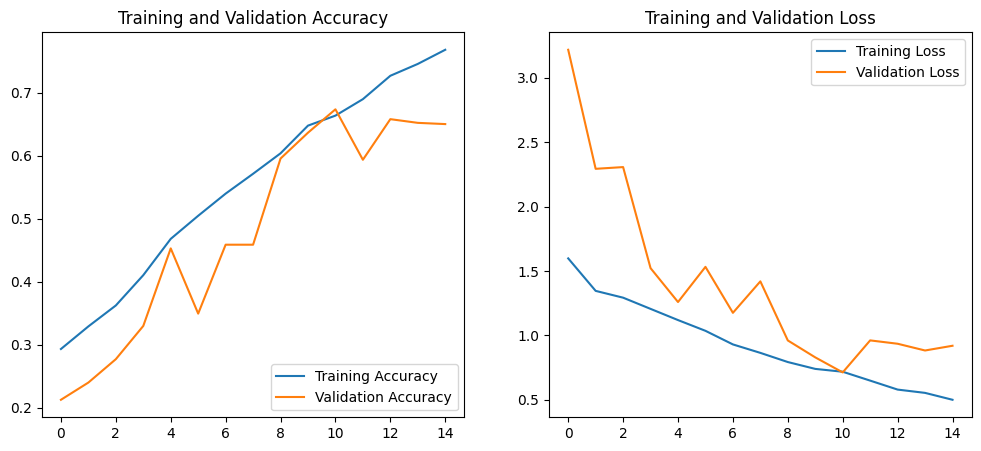

In [9]:
# Plot Training and Validation curves
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.show()

In [10]:
from tensorflow.keras import applications

# 1. Setup Data Augmentation to prevent overfitting
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15)
])

# 2. Load pre-trained MobileNetV2 base model
# We use weights pre-trained on ImageNet and exclude the top classification layer
base_model = applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the base model layers initially to preserve learned features
base_model.trainable = False

# 3. Build Transfer Learning Model
transfer_model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    data_augmentation,
    # MobileNetV2 expects inputs normalized in [-1, 1], so we use its built-in preprocessing
    layers.Lambda(applications.mobilenet_v2.preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')
])

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

/tmp/ipykernel_2653/2276499256.py:12: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,980 (9.24 MB)

 Trainable params: 164,740 (643.52 KB)

 Non-trainable params: 2,258,240 (8.61 MB)

In [11]:
# Train the transfer model (Phase 1: training top layers)
print("Training the classification head...")
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Training the classification head...
Epoch 1/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.3196 - loss: 1.7836 - val_accuracy: 0.4453 - val_loss: 1.3850
Epoch 2/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.3569 - loss: 1.4917 - val_accuracy: 0.4395 - val_loss: 1.2621
Epoch 3/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.3721 - loss: 1.3784 - val_accuracy: 0.4473 - val_loss: 1.2644
Epoch 4/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.4038 - loss: 1.3098 - val_accuracy: 0.4395 - val_loss: 1.2482
Epoch 5/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4163 - loss: 1.2924 - val_accuracy: 0.4688 - val_loss: 1.2303
Epoch 6/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4121 - loss: 1.2751 - val_accuracy: 0.4570 - val_loss: 1.2161
Epoch 7/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4399 - loss: 1.2530 - val_accuracy: 0.4570 - val_loss: 1.1958
Epoch 8/10
128/128 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accur

In [12]:
# Phase 2: Fine-Tuning
# Unfreeze the base model and train with a very low learning rate
base_model.trainable = True

print(f"Number of layers in the base model: {len(base_model.layers)}")

# Fine-tune from this layer onwards
fine_tune_at = 100

# Freeze all the layers before the 'fine_tune_at' layer
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # Low learning rate for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning the model...")
history_fine = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Number of layers in the base model: 154
Fine-tuning the model...
Epoch 1/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step - accuracy: 0.3271 - loss: 1.4452 - val_accuracy: 0.4473 - val_loss: 1.2385
Epoch 2/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3474 - loss: 1.4126 - val_accuracy: 0.4355 - val_loss: 1.3294
Epoch 3/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3582 - loss: 1.3843 - val_accuracy: 0.4297 - val_loss: 1.3662
Epoch 4/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3562 - loss: 1.3742 - val_accuracy: 0.4414 - val_loss: 1.3760
Epoch 5/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3606 - loss: 1.3705 - val_accuracy: 0.4316 - val_loss: 1.3702
Epoch 6/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3740 - loss: 1.3602 - val_accuracy: 0.4258 - val_loss: 1.3692
Epoch 7/15
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3896 - loss: 1.3278 - val_accuracy: 0.4160 - val_loss: 1.3478
Epoch 8/15
128/128 ━━━━━━━━━━━━

In [13]:
# Evaluate the improved model on the test dataset
test_loss, test_acc = transfer_model.evaluate(test_ds)
print(f"Improved Test Loss: {test_loss:.4f}")
print(f"Improved Test Accuracy: {test_acc:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4553 - loss: 1.2877
Improved Test Loss: 1.2877
Improved Test Accuracy: 0.4553


In [14]:
# Rebuild the Transfer Learning Model with a Resizing layer to 224x224
from tensorflow.keras import applications, layers, models
import tensorflow as tf

# 1. Setup Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2)
])

# 2. Load pre-trained MobileNetV2 base model with 224x224 input expectations
base_model = applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# 3. Build Model Pipeline with explicit Resizing
transfer_model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    data_augmentation,
    layers.Resizing(224, 224), # Upscale 64x64 to 224x224 for optimal feature extraction
    layers.Lambda(applications.mobilenet_v2.preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')
])

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,972 (9.87 MB)

 Trainable params: 329,476 (1.26 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

In [15]:
# Phase 1: Train the classification head first
print("Training the classification head with 224x224 inputs...")
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8
)

Training the classification head with 224x224 inputs...
Epoch 1/8
128/128 ━━━━━━━━━━━━━━━━━━━━ 15s 75ms/step - accuracy: 0.3684 - loss: 1.6401 - val_accuracy: 0.4004 - val_loss: 1.2984
Epoch 2/8
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.4370 - loss: 1.3280 - val_accuracy: 0.4512 - val_loss: 1.2111
Epoch 3/8
128/128 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - accuracy: 0.4351 - loss: 1.2702 - val_accuracy: 0.4902 - val_loss: 1.1761
Epoch 4/8
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.4585 - loss: 1.2137 - val_accuracy: 0.4668 - val_loss: 1.2051
Epoch 5/8
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.4597 - loss: 1.1948 - val_accuracy: 0.5215 - val_loss: 1.1175
Epoch 6/8
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - accuracy: 0.4783 - loss: 1.1786 - val_accuracy: 0.5000 - val_loss: 1.1423
Epoch 7/8
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step - accuracy: 0.4780 - loss: 1.1671 - val_accuracy: 0.4922 - val_loss: 1.1340
Epoch 8/8
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms

In [18]:
# Phase 2: Unfreeze deeper layers of the base model for more expressive representation
base_model.trainable = True

# Unfreeze from layer 50 onwards (more capacity to adapt features)
fine_tune_at = 50
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-5), # Keep learning rate very low to protect weights
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning deeper layers of the model with upscaled inputs...")
history_fine = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Fine-tuning deeper layers of the model with upscaled inputs...
Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 27s 115ms/step - accuracy: 0.8333 - loss: 0.4177 - val_accuracy: 0.7734 - val_loss: 0.5749
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - accuracy: 0.8413 - loss: 0.3974 - val_accuracy: 0.7793 - val_loss: 0.5370
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 13s 105ms/step - accuracy: 0.8469 - loss: 0.3829 - val_accuracy: 0.8008 - val_loss: 0.5080
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - accuracy: 0.8533 - loss: 0.3734 - val_accuracy: 0.7754 - val_loss: 0.5523
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 13s 100ms/step - accuracy: 0.8599 - loss: 0.3637 - val_accuracy: 0.7949 - val_loss: 0.5156
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - accuracy: 0.8611 - loss: 0.3500 - val_accuracy: 0.8066 - val_loss: 0.4968
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - accuracy: 0.8635 - loss: 0.3421 - val_accuracy: 0.7832 - val_loss: 0.5241
Epoch 8/20
128/128 ━

In [17]:
# Re-evaluate the improved high-res model on the test dataset
test_loss, test_acc = transfer_model.evaluate(test_ds)
print(f"Final High-Res Test Loss: {test_loss:.4f}")
print(f"Final High-Res Test Accuracy: {test_acc:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.7195 - loss: 0.6461
Final High-Res Test Loss: 0.6461
Final High-Res Test Accuracy: 0.7195


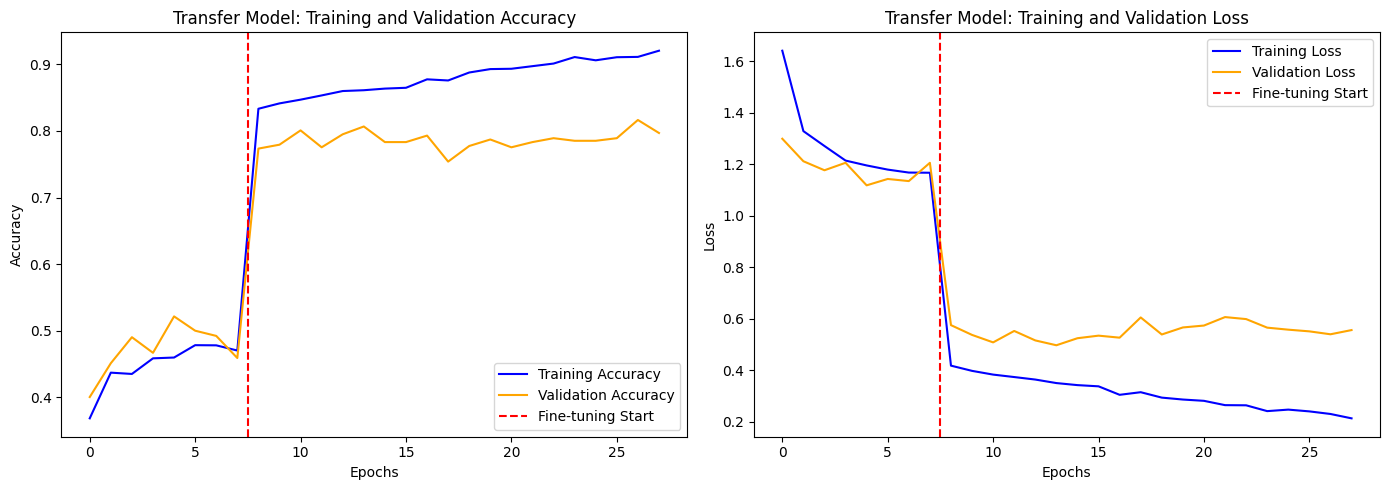

In [19]:
import matplotlib.pyplot as plt

# Combine history metrics from Phase 1 and Phase 2
tot_acc = history_transfer.history['accuracy'] + history_fine.history['accuracy']
tot_val_acc = history_transfer.history['val_accuracy'] + history_fine.history['val_accuracy']
tot_loss = history_transfer.history['loss'] + history_fine.history['loss']
tot_val_loss = history_transfer.history['val_loss'] + history_fine.history['val_loss']

epochs_range = range(len(tot_acc))

plt.figure(figsize=(14, 5))

# Accuracy curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, tot_acc, label='Training Accuracy', color='blue')
plt.plot(epochs_range, tot_val_acc, label='Validation Accuracy', color='orange')
plt.axvline(x=len(history_transfer.history['accuracy']) - 0.5, color='red', linestyle='--', label='Fine-tuning Start')
plt.legend(loc='lower right')
plt.title('Transfer Model: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

# Loss curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, tot_loss, label='Training Loss', color='blue')
plt.plot(epochs_range, tot_val_loss, label='Validation Loss', color='orange')
plt.axvline(x=len(history_transfer.history['accuracy']) - 0.5, color='red', linestyle='--', label='Fine-tuning Start')
plt.legend(loc='upper right')
plt.title('Transfer Model: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()

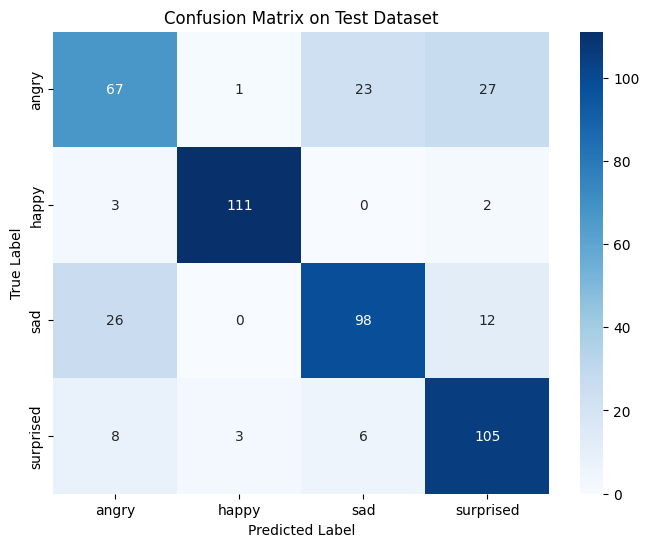


Classification Report:
              precision    recall  f1-score   support

       angry       0.64      0.57      0.60       118
       happy       0.97      0.96      0.96       116
         sad       0.77      0.72      0.75       136
   surprised       0.72      0.86      0.78       122

    accuracy                           0.77       492
   macro avg       0.78      0.78      0.77       492
weighted avg       0.77      0.77      0.77       492



In [20]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Retrieve all true labels and predictions for the test dataset
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = transfer_model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix on Test Dataset')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Print classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

In [21]:
%%writefile app.py
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image
import os

# Configure Streamlit page
st.set_page_config(
    page_title="Facial Emotion Classifier",
    page_icon="🎭",
    layout="centered"
)

# Title and Description
st.title("🎭 Facial Emotion Classifier")
st.write("Upload an image, and our fine-tuned MobileNetV2 model will predict the underlying emotion.")

# Set up class names mapping from training
class_names = ['angry', 'happy', 'sad', 'surprised']

# Load the trained model
@st.cache_resource
def load_emotion_model():
    # In a local deployment environment, you would save the model using model.save('emotion_model.keras')
    # and load it back. In this Colab sandbox context, we point to that expectation:
    model_path = 'emotion_model.keras'
    if os.path.exists(model_path):
        return tf.keras.models.load_model(model_path)
    else:
        st.warning("Model file 'emotion_model.keras' not found. Please save your model first using `transfer_model.save('emotion_model.keras')`.")
        return None

model = load_emotion_model()

# Image Uploader / Camera Input
uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])
camera_file = st.camera_input("Or take a picture directly")

target_file = uploaded_file if uploaded_file is not None else camera_file

if target_file is not None:
    # Display the uploaded image
    image = Image.open(target_file).convert("RGB")
    st.image(image, caption='Target Image', use_container_width=True)

    if model is not None:
        with st.spinner('Analyzing emotion...'):
            # Preprocess the image for MobileNetV2 (matching our training pipeline)
            # 1. Resize to 224x224
            resized_image = image.resize((224, 224))
            img_array = tf.keras.utils.img_to_array(resized_image)

            # 2. Add batch dimension
            img_array = np.expand_dims(img_array, axis=0)

            # 3. Apply preprocess input (Lambda layer equivalent preprocessing)
            processed_img = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)

            # Perform inference
            predictions = model.predict(processed_img)
            scores = tf.nn.softmax(predictions[0]).numpy() # If final layer was linear, otherwise raw prediction is softmax
            # Since final layer of our model is already activation='softmax', we can directly use predictions[0]
            raw_scores = predictions[0]

            best_class_idx = np.argmax(raw_scores)
            best_class = class_names[best_class_idx]
            confidence = raw_scores[best_class_idx] * 100

            # Display Result
            st.success(f"Predicted Emotion: **{best_class.upper()}** ({confidence:.2f}% Confidence)")

            # Detailed confidence breakdown
            st.write("### Probability Breakdown")
            for emotion, score in zip(class_names, raw_scores):
                st.write(f"{emotion.capitalize()}")
                st.progress(float(score))
                st.caption(f"Confidence: {score*100:.2f}%")


Writing app.py


In [22]:
# Save the trained model to disk so that app.py can successfully load it
transfer_model.save('emotion_model.keras')
print("Model saved as 'emotion_model.keras' successfully!")

Model saved as 'emotion_model.keras' successfully!
